# Прогноз недельных продаж Walmart: ARIMA и SARIMAX

**Данные**: недельные продажи одного магазина Walmart за 2010–2012 гг. (`Walmart_store_sales.csv`, 143 наблюдения).

**Задача**: построить прогноз недельных продаж с помощью моделей `ARIMA` / `SARIMAX` с оптимальными параметрами.

**План работы**
1. Загрузка данных, приведение к нужному формату, график ряда.
2. Тест Дики–Фуллера на стационарность (определение `d`).
3. Коррелограммы ACF и PACF, выбор модели и параметров вручную.
4. Обучение выбранной модели на тренировочной выборке, прогноз на тестовой.
5. Модель `auto_arima`.
6. Подбор параметров перебором (минимизация `MAE`).
7. Модель с подобранными перебором параметрами.
8. Сравнение моделей по `MAE` и `R2` (вместе с базовым прогнозом константой), выбор лучшей.
9. Выводы.

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import itertools
import time

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.model_selection import train_test_split

from pmdarima import auto_arima
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, r2_score

import warnings
warnings.filterwarnings('ignore')

## 1. Загрузка и подготовка данных

На первом этапе загрузим данные и проверим их структуру. Важно убедиться, что даты идут с постоянным шагом, а пропуски отсутствуют, так как это критично для анализа временных рядов.

In [ ]:
# загружаем данные из файла
data = pd.read_csv('Walmart_store_sales.csv')
data.info()
data.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143 entries, 0 to 142
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          143 non-null    object 
 1   Weekly_Sales  143 non-null    float64
dtypes: float64(1), object(1)
memory usage: 2.4+ KB


,Date,Weekly_Sales
0,05-02-2010,1643690.90
1,12-02-2010,1641957.44
2,19-02-2010,1611968.17
3,26-02-2010,1409727.59
4,05-03-2010,1554806.68


In [ ]:
# колонка Date хранится как строка в формате день-месяц-год, приводим к типу datetime
# и задаем ее в качестве индекса
data['Date'] = pd.to_datetime(data['Date'], format='%d-%m-%Y')
data.set_index('Date', inplace=True)

# проверим, что даты идут строго раз в неделю (без пропусков и дубликатов)
print('Шаг по датам:', data.index.to_series().diff().value_counts().to_dict())
print('Пропуски:', data.isna().sum().to_dict())

# задаем частоту ряда (недели, заканчивающиеся в пятницу)
data = data.asfreq('W-FRI')
print('Период:', data.index.min().date(), '-', data.index.max().date(), '| наблюдений:', len(data))
data.describe()

Шаг по датам: {Timedelta('7 days 00:00:00'): 142}
Пропуски: {'Weekly_Sales': 0}
Период: 2010-02-05 - 2012-10-26 | наблюдений: 143


,Weekly_Sales
count,1.430000e+02
mean,1.555264e+06
std,1.559808e+05
min,1.316899e+06
25%,1.458105e+06
50%,1.534850e+06
75%,1.614892e+06
max,2.387950e+06


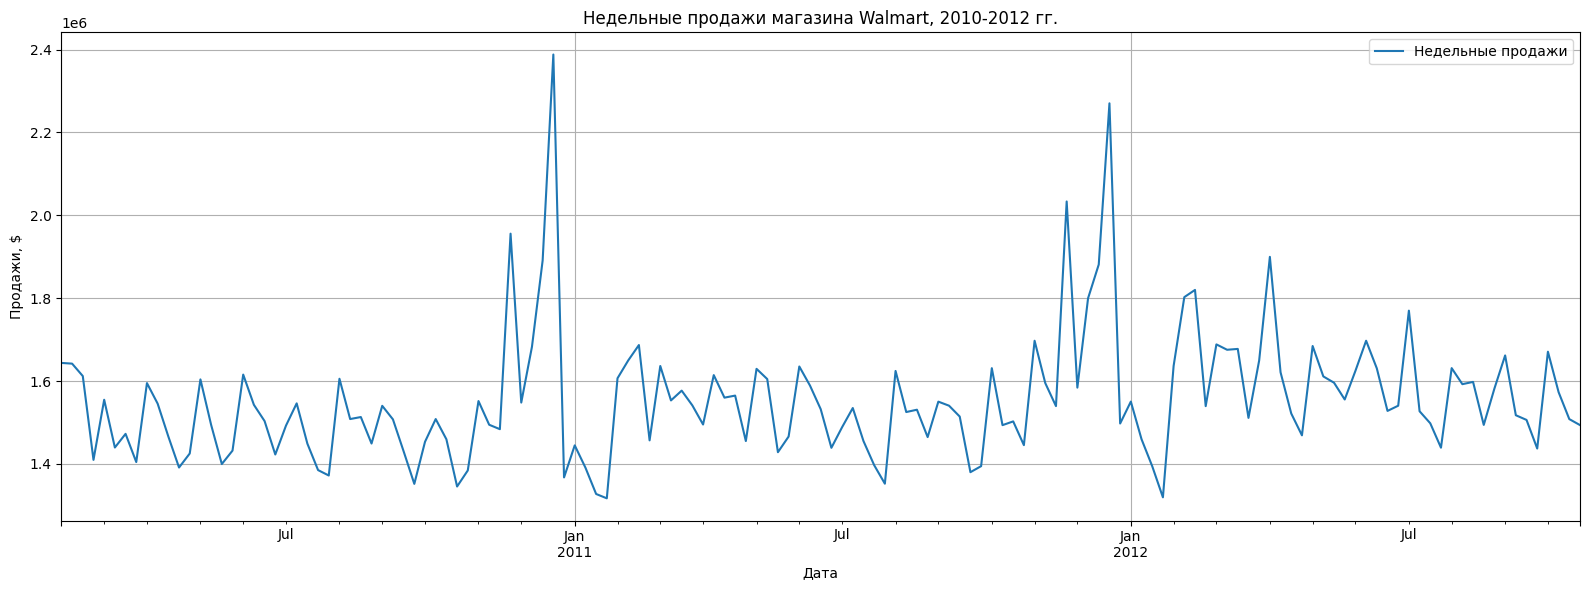

In [ ]:
# график исходного временного ряда
data.plot(figsize=(16, 6),
          grid=True,
          xlabel='Дата',
          ylabel='Продажи, $',
          title='Недельные продажи магазина Walmart, 2010-2012 гг.')
plt.legend(['Недельные продажи'])
plt.tight_layout()
plt.show()

На графике видно, что явного тренда нет: ряд колеблется около среднего уровня (≈1,55 млн). Наиболее заметны **ежегодные пики** в конце ноября – декабре (Black Friday, Рождество; максимум ≈2,39 млн в неделю 24.12.2010), то есть присутствует годовая сезонность с периодом **52 недели**. Остальные всплески – предпраздничные недели (Пасха, День благодарения и т.д.).

## 2. Проверка ряда на стационарность (тест Дики–Фуллера)

In [ ]:
def adf_check(series, name):
    res = adfuller(series.values)
    print(f'{name}')
    print(f'  ADF-статистика = {res[0]:.4f}, p-value = {res[1]:.6f}, использовано лагов = {res[2]}')
    for k, v in res[4].items():
        print(f'  критическое значение {k}: {v:.4f}')
    print('  ->', 'Ряд стационарный' if res[1] < 0.05 else 'Ряд нестационарный')
    print()

# исходный ряд
adf_check(data['Weekly_Sales'], 'Исходный ряд')

# для сравнения - ряд первых разностей
data_diff = data['Weekly_Sales'].diff(periods=1).dropna()
adf_check(data_diff, 'Ряд первых разностей')

Исходный ряд
  ADF-статистика = -5.1022, p-value = 0.000014, использовано лагов = 4
  критическое значение 1%: -3.4786
  критическое значение 5%: -2.8827
  критическое значение 10%: -2.5781
  -> Ряд стационарный

Ряд первых разностей
  ADF-статистика = -7.2616, p-value = 0.000000, использовано лагов = 7
  критическое значение 1%: -3.4801
  критическое значение 5%: -2.8834
  критическое значение 10%: -2.5784
  -> Ряд стационарный



**Результат теста:**
- p-value исходного ряда < 0.05, следовательно, нулевая гипотеза о нестационарности отвергается. **Ряд стационарен.**
- Это означает, что параметр дифференцирования `d = 0`. Применение разностного преобразования не требуется и может привести к "передифференцированию" и потере информации.
- Ряд первых разностей также стационарен, но для дальнейшего анализа мы будем использовать исходный ряд, так как он уже стационарен.

## 3. Коррелограммы ACF и PACF

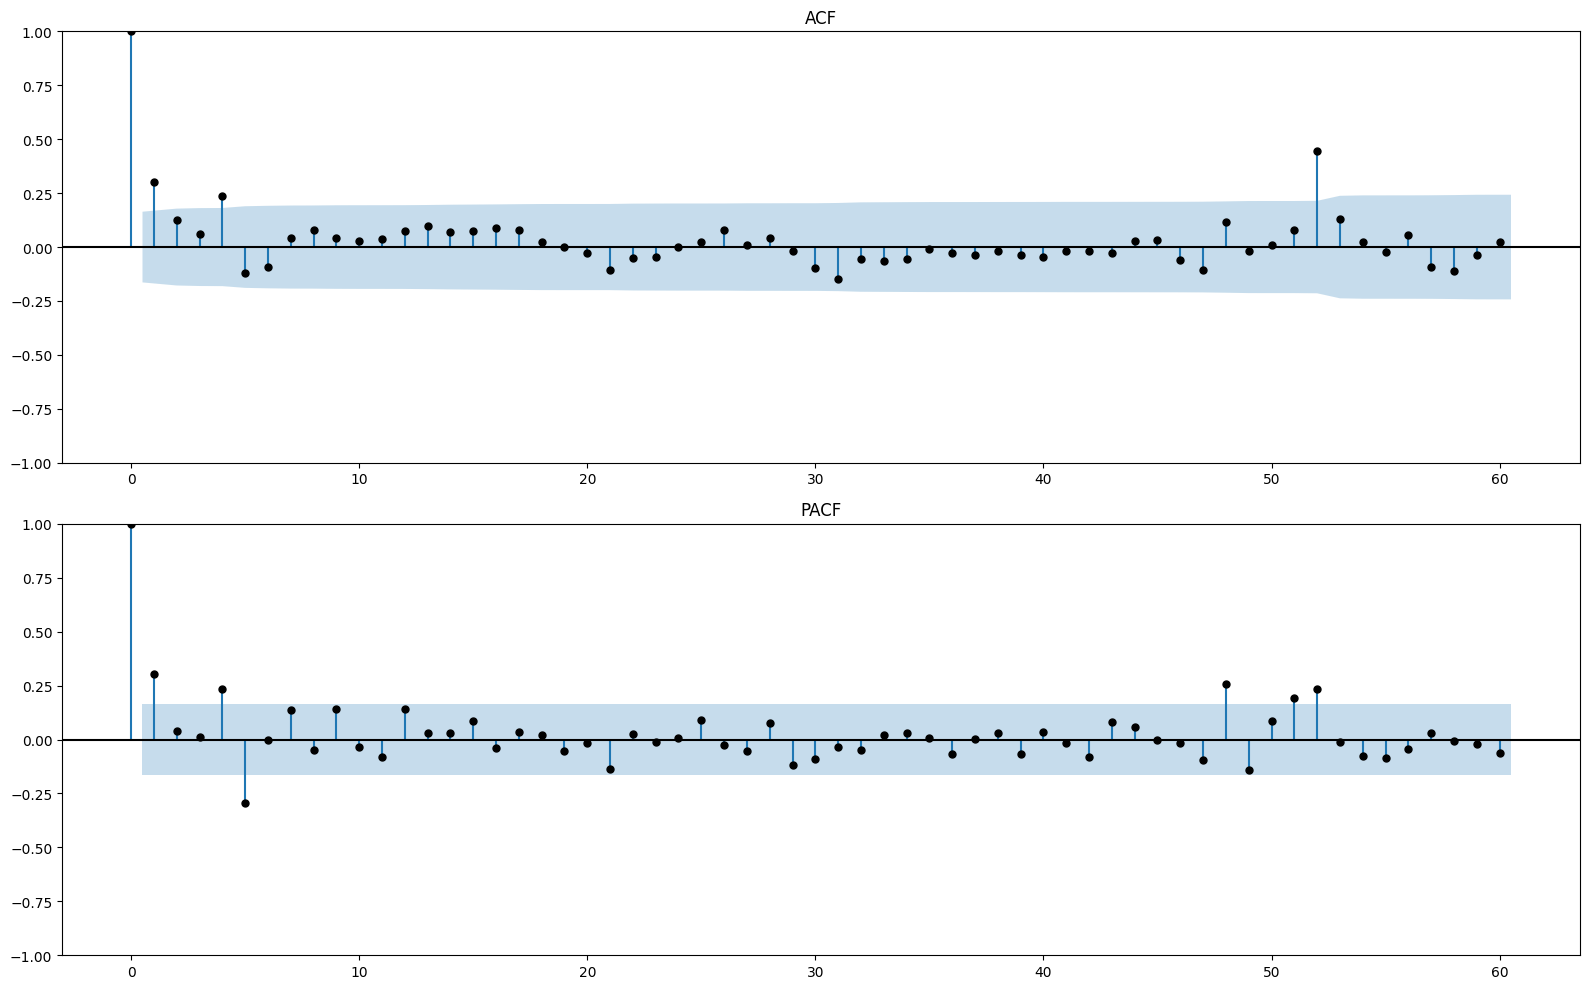

In [ ]:
# коррелограммы для исходного (стационарного) ряда
fig, ax = plt.subplots(2, 1, figsize=(16, 10))
plot_acf(data['Weekly_Sales'].values, lags=60, color='black', ax=ax[0])
plot_pacf(data['Weekly_Sales'].values, lags=60, color='black', method='ywm', ax=ax[1])
ax[0].set_title('ACF')
ax[1].set_title('PACF')
plt.tight_layout()
plt.show()

**Анализ коррелограмм:**
- **ACF:** значимы лаги **1, 4 и 52**. Это отдельные всплески, а не плавное затухание и не «обрыв после лагов 1–4»: лаги 2 и 3 лежат внутри доверительного интервала. Пик на лаге 52 соответствует годовой сезонности (52 недели).
- **PACF:** значимы лаги **1 и 4**, лаги 2 и 3 незначимы (это же видно по p-value коэффициентов `ar.L2` и `ar.L3` в summary модели ниже).

**Выбор модели по коррелограммам:**
- `d = 0` — ряд стационарен (тест Дики–Фуллера).
- `p = 4` — максимальный значимый лаг PACF равен 4. Лаги 2 и 3 при этом незначимы, но по стандартному правилу берётся максимальный значимый лаг.
- `q = 0` — формально по стандартному правилу `q` равен последнему значимому лагу ACF (то есть 4), но здесь значимы лишь отдельные лаги 1 и 4, чёткого обрыва нет. Такие всплески ACF уже объясняются авторегрессией `AR(4)`, поэтому для базовой модели берём `q = 0`. Это упрощение; варианты с `q > 0` проверяются в `auto_arima` и в переборе (раздел 8, `q ∈ [0, 2]`).
- `P = 0, Q = 1, m = 52` — значимый пик ACF на сезонном лаге 52 указывает на сезонную MA-компоненту.
- Константа (`trend='c'`) включается во все модели: средний уровень ряда ≈ 1,55 млн $, и без константы модель пришлось бы строить для ряда без среднего.

Итак, вручную выбираем **`SARIMAX(4, 0, 0)(0, 0, 1, 52)`** с константой. Это базовый вариант, выбранный по коррелограммам; ниже он сравнивается с `auto_arima`, перебором и базовым прогнозом.


## 4. Разбиение на обучающую и тестовую выборки

Разделим данные на обучающую (80%) и тестовую (20%) выборки. Важно использовать `shuffle=False`, чтобы сохранить временной порядок данных. Тестовая выборка будет содержать последние 20% наблюдений, что имитирует прогнозирование на будущие периоды.

In [ ]:
# разбиваем ряд на обучающую и тестовую выборки в соотношении 80 на 20 (без перемешивания!)
x_train, x_test = train_test_split(data['Weekly_Sales'], test_size=.2, shuffle=False)
print('Обучающая:', x_train.index.min().date(), '-', x_train.index.max().date(), len(x_train))
print('Тестовая :', x_test.index.min().date(), '-', x_test.index.max().date(), len(x_test))

# начальная и конечная точки прогноза
start = len(x_train)
end = len(x_train) + len(x_test) - 1

Обучающая: 2010-02-05 - 2012-04-06 114
Тестовая : 2012-04-13 - 2012-10-26 29


In [ ]:
# функция построения графика прогноза
def plot_prediction(train, test, pred, title='Обучающая выборка и прогноз'):
    plt.figure(figsize=(16, 6))
    plt.plot(train, color='black')
    plt.plot(test, color='green')
    plt.plot(pred, color='red')
    plt.title(title)
    plt.legend(['Обучающая выборка', 'Тестовая выборка', 'Прогноз'])
    plt.ylabel('Продажи, $')
    plt.xlabel('Дата')
    plt.grid()
    plt.tight_layout()
    plt.show()

# таблица с метриками и функция ее заполнения
df_model = pd.DataFrame({'model_name': [], 'params': [], 'R2': [], 'MAE': []})
predictions_all = {}

def model_char(test, pred, model_name, params=''):
    pred = np.asarray(pred)
    mae = mean_absolute_error(test, pred)
    r2 = r2_score(test, pred)
    df_model.loc[len(df_model.index)] = [model_name, params, r2, mae]
    predictions_all[model_name] = pred
    return df_model

**Особенности тестовой выборки и базовый прогноз.**

Тестовый период — с 20.04.2012 по 26.10.2012, то есть он **не включает ноябрь–декабрь**, где в обучающей выборке находятся главные пики (максимум 2,39 млн в неделю 24.12.2010). В тесте максимум равен 1,77 млн (неделя 4 июля), а стандартное отклонение ≈ 81 тыс., то есть ряд колеблется лишь примерно на ±5% вокруг среднего (≈1,57 млн). Поэтому низкий R² здесь объясняется малой дисперсией теста, а не «непредсказуемыми праздничными пиками».

Чтобы оценить пользу моделей, добавим **базовый прогноз**: константа, равная среднему по обучающей выборке. Модель имеет смысл, только если заметно обходит его по MAE.


In [ ]:
# базовый прогноз: постоянное значение = среднее по обучающей выборке
baseline_pred = np.full(len(x_test), x_train.mean())
model_char(x_test, baseline_pred, 'Baseline (среднее train)', f'const={x_train.mean():,.0f}')


,model_name,params,R2,MAE
0,Baseline (среднее train),"const=1,551,089",-0.066782,67816.823376


## 5. Модель 1: ARIMA(4, 0, 0) – параметры выбраны по коррелограммам

Параметры выбраны так же, как в разделе 3: `p=4` (максимальный значимый лаг PACF), `d=0` (ряд стационарен), `q=0` (на ACF значимы лишь отдельные лаги 1 и 4 без чёткого обрыва, они уже объясняются `AR(4)`). Модель `ARIMA(4, 0, 0)` из `statsmodels` включает константу по умолчанию.


                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  114
Model:                 ARIMA(4, 0, 0)   Log Likelihood               -1525.856
Date:                Wed, 07 Oct 2026   AIC                           3063.712
Time:                        20:35:01   BIC                           3080.129
Sample:                             0   HQIC                          3070.375
                                - 114                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.551e+06   3.65e+04     42.549      0.000    1.48e+06    1.62e+06
ar.L1          0.2978      0.076      3.905      0.000       0.148       0.447
ar.L2          0.0437      0.128      0.340      0.7

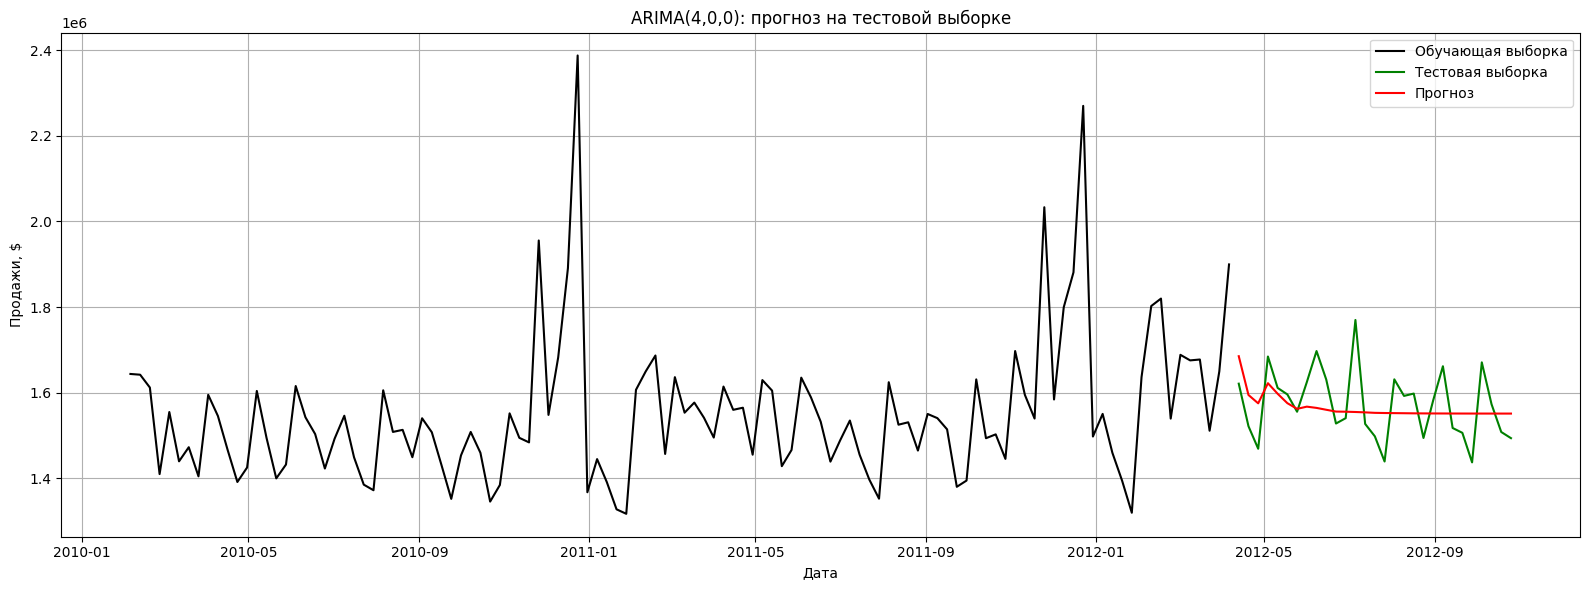

,model_name,params,R2,MAE
0,Baseline (среднее train),"const=1,551,089",-0.066782,67816.823376
1,ARIMA,"(4,0,0)",0.035195,64124.847068


In [ ]:
# в ARIMA из statsmodels константа включена по умолчанию
model_arima = ARIMA(x_train.values, order=(4, 0, 0))
model_arima_fit = model_arima.fit()
print(model_arima_fit.summary())

predictions = pd.Series(model_arima_fit.predict(start, end), index=x_test.index)
plot_prediction(x_train, x_test, predictions, 'ARIMA(4,0,0): прогноз на тестовой выборке')
model_char(x_test, predictions, 'ARIMA', '(4,0,0)')

## 6. Модель 2: SARIMAX(4, 0, 0)(0, 0, 1, 52) – с учетом годовой сезонности

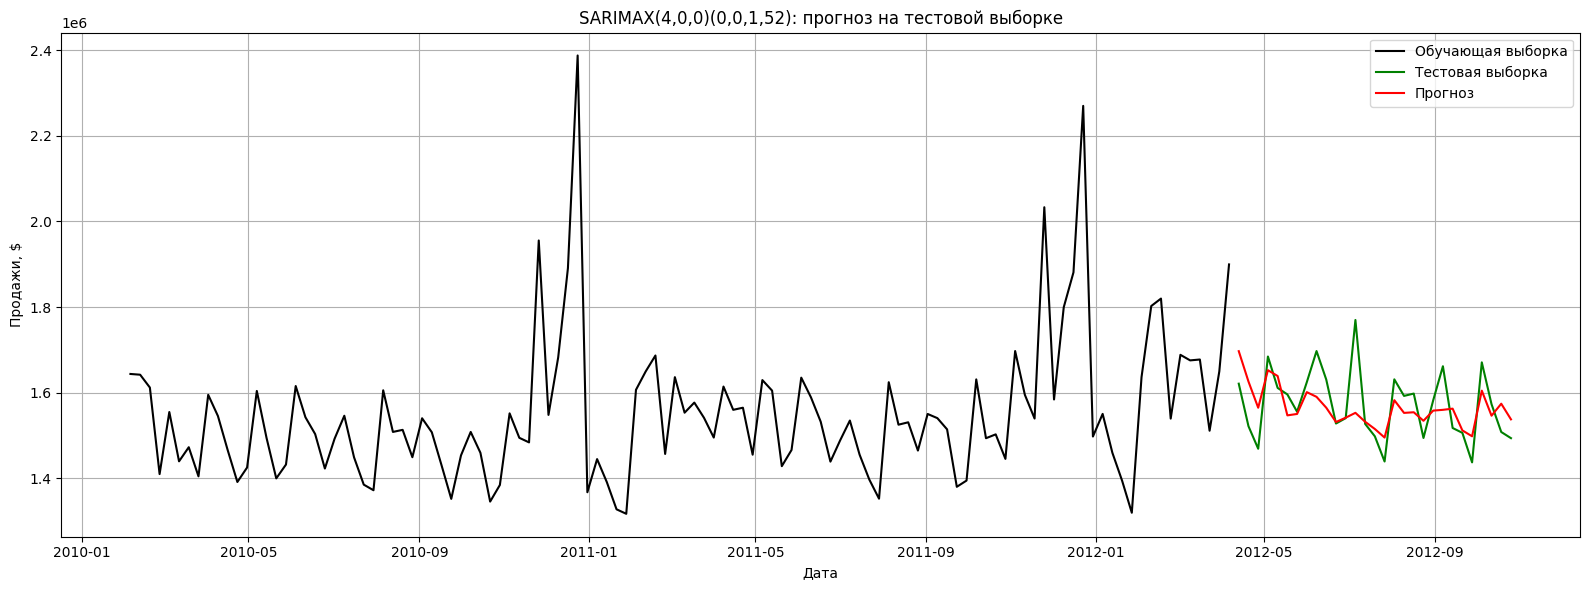

,model_name,params,R2,MAE
0,Baseline (среднее train),"const=1,551,089",-0.066782,67816.823376
1,ARIMA,"(4,0,0)",0.035195,64124.847068
2,SARIMAX,"(4,0,0)(0,0,1,52)",0.279819,51686.696482


In [ ]:
model_sarimax = SARIMAX(x_train.values,
                        order=(4, 0, 0),
                        seasonal_order=(0, 0, 1, 52),
                        trend='c')   # константа: в SARIMAX по умолчанию её нет (в ARIMA и auto_arima есть)
model_sarimax_fit = model_sarimax.fit(disp=False)

predictions = pd.Series(model_sarimax_fit.predict(start, end), index=x_test.index)
plot_prediction(x_train, x_test, predictions, 'SARIMAX(4,0,0)(0,0,1,52): прогноз на тестовой выборке')
model_char(x_test, predictions, 'SARIMAX', '(4,0,0)(0,0,1,52)')

**Анализ модели SARIMAX(4,0,0)(0,0,1,52) с константой:**

Компоненты модели:
- `p=4` — несезонная авторегрессия (значимые лаги PACF — 1 и 4, максимальный — 4);
- `d=0` — ряд стационарен;
- `q=0` — несезонной скользящей средней нет (обоснование в разделе 3);
- `P=0, D=0, Q=1` — сезонная скользящая средняя первого порядка (пик ACF на лаге 52);
- `m=52` — период сезонности;
- `trend='c'` — константа (в `SARIMAX` её нужно включать явно).

**Результат:** MAE = 51 687, R² = 0.280. Это ≈24% лучше базового прогноза константой (MAE = 67 817, R² = −0.067) и лучше, чем `ARIMA(4,0,0)` (64 125) и `auto_arima` (52 545). Модель объясняет около 28% дисперсии тестовой выборки.

**Роль константы.** Без константы эта же модель давала отрицательный R² (−1.49): ряд со средним ≈ 1,55 млн моделировался без среднего, и прогноз систематически смещался. После добавления `trend='c'` при тех же порядках `(4,0,0)(0,0,1,52)` модель стала второй по качеству. Значит, плохой результат первого запуска объяснялся отсутствием константы, а не выбором сезонной MA-компоненты.

**Ограничения:** на обучающей выборке всего ≈2,2 годовых цикла (114 недель), поэтому сезонная часть с периодом 52 оценивается по малому числу повторений. Кроме того, в тесте (апрель–октябрь 2012) нет ноябрьско-декабрьских пиков, так что способность модели прогнозировать главные сезонные пики этим тестом не проверяется.


## 7. Модель 3: auto_arima

`auto_arima` автоматически подбирает параметры SARIMA, минимизируя AIC. Задаём `d=0` (ряд стационарен), `m=52` (годовая сезонность), ограничиваем порядки (`max_p=6, max_q=6, max_P=1, max_Q=1`), так как на 114 точках большие порядки не имеют смысла.

In [ ]:
# автоматический подбор параметров; d=0 по результатам теста Дики-Фуллера,
# сезонность m=52. Диапазоны ограничены, т.к. на 114 точках 52-недельный период
# оценивается всего по ~2 сезонам и большие порядки не имеют смысла
auto_model = auto_arima(x_train.values,
                        start_p=0, start_q=0,
                        max_p=6, max_q=6,
                        d=0,
                        seasonal=True, m=52,
                        start_P=0, start_Q=0,
                        max_P=1, max_Q=1,
                        D=0,
                        max_order=10,
                        stepwise=True,
                        information_criterion='aic',
                        error_action='ignore',
                        suppress_warnings=True,
                        trace=True)
print(auto_model.summary())

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,0,0)[52] intercept   : AIC=3072.280, Time=0.06 sec
 ARIMA(1,0,0)(1,0,0)[52] intercept   : AIC=3047.250, Time=5.51 sec
 ARIMA(0,0,1)(0,0,1)[52] intercept   : AIC=3041.293, Time=0.81 sec
 ARIMA(0,0,0)(0,0,0)[52]             : AIC=3576.884, Time=0.01 sec
 ARIMA(0,0,1)(0,0,0)[52] intercept   : AIC=3065.019, Time=0.02 sec
 ARIMA(0,0,1)(1,0,1)[52] intercept   : AIC=3043.180, Time=1.67 sec
 ARIMA(0,0,1)(1,0,0)[52] intercept   : AIC=3066.401, Time=0.90 sec
 ARIMA(0,0,0)(0,0,1)[52] intercept   : AIC=3045.777, Time=0.58 sec
 ARIMA(1,0,1)(0,0,1)[52] intercept   : AIC=3037.792, Time=1.02 sec
 ARIMA(1,0,1)(0,0,0)[52] intercept   : AIC=3064.135, Time=0.05 sec
 ARIMA(1,0,1)(1,0,1)[52] intercept   : AIC=3035.328, Time=3.78 sec
 ARIMA(1,0,1)(1,0,0)[52] intercept   : AIC=3035.336, Time=3.34 sec
 ARIMA(1,0,0)(1,0,1)[52] intercept   : AIC=3035.871, Time=1.51 sec
 ARIMA(2,0,1)(1,0,1)[52] intercept   : AIC=3033.698, Time=6.77 sec
 ARIMA(2,0,1)(0,0,1

Модель выбрала параметры **(4,0,2)(1,0,0,52)**: `p=4, d=0, q=2` — несезонная часть; `P=1, D=0, Q=0, m=52` — сезонная.

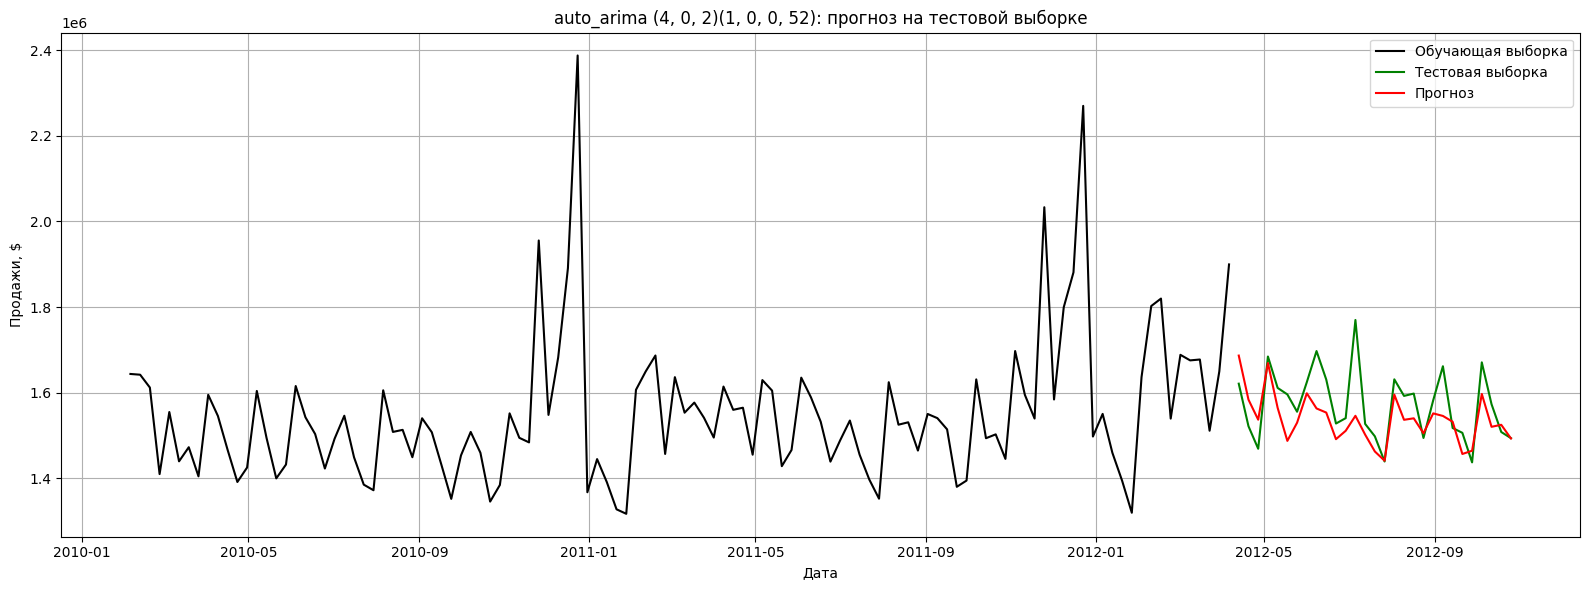

,model_name,params,R2,MAE
0,Baseline (среднее train),"const=1,551,089",-0.066782,67816.823376
1,ARIMA,"(4,0,0)",0.035195,64124.847068
2,SARIMAX,"(4,0,0)(0,0,1,52)",0.279819,51686.696482
3,auto_arima,"(4, 0, 2)(1, 0, 0, 52)",0.235638,52544.815109


In [ ]:
# прогноз на тестовой выборке
predictions = pd.Series(auto_model.predict(n_periods=len(x_test)), index=x_test.index)
auto_params = f'{auto_model.order}{auto_model.seasonal_order}'
plot_prediction(x_train, x_test, predictions, f'auto_arima {auto_params}: прогноз на тестовой выборке')
model_char(x_test, predictions, 'auto_arima', auto_params)

**Метрики auto_arima:** R² = 0.236, MAE = 52544.82.

Модель показала результат лучше, чем `ARIMA(4,0,0)`; сравнение с остальными моделями и с базовым прогнозом — в разделе 10. Прогноз колеблется вместе с тестовой выборкой, хотя на резких пиках всё ещё есть расхождения. R² = 0.236 означает, что модель объясняет около 24% дисперсии тестовой выборки.

**Замечание.** В summary `auto_arima` есть предупреждение о почти вырожденной ковариационной матрице (огромное число обусловленности), поэтому p-value отдельных коэффициентов там ненадёжны. Причина — масштаб: константа ≈ 1,5 млн, а шум на порядки меньше. Если пересчитать ряд в миллионы долларов, подгонка станет устойчивее (в этой работе масштаб не менялся, чтобы метрики оставались в долларах).


## 8. Подбор параметров перебором (минимизация MAE)

Перебираем параметры SARIMAX и для каждой комбинации считаем MAE на тестовой выборке. В отличие от AIC (который использует auto_arima), MAE измеряет фактическую ошибку прогноза в долларах — это более интерпретируемо для бизнес-задачи.

Сетка: `p ∈ [0,4]`, `q ∈ [0,2]`, `(P,Q) ∈ {(0,0),(0,1),(1,0),(1,1)}`, `d=0`, `D=0`, `m=52`. Всего 60 комбинаций.

In [ ]:
# сетка параметров: d=0 (по тесту Дики-Фуллера), D=0, m=52
p_values = range(0, 5)
d_values = [0]
q_values = range(0, 3)
PQ_values = [(0, 0), (0, 1), (1, 0), (1, 1)]   # сезонные (P, Q)
D_values = [0]
m_values = [52]

param_combinations = [(p, d, q, P, D, Q, m)
                      for p, d, q in itertools.product(p_values, d_values, q_values)
                      for (P, Q) in PQ_values
                      for D in D_values
                      for m in m_values]
print('Число комбинаций:', len(param_combinations))

best_mae = np.inf
best_params = None
results = []
t0 = time.time()

for i, params in enumerate(param_combinations, 1):
    order, seasonal_order = params[:3], params[3:]
    try:
        model = SARIMAX(x_train.values, order=order, seasonal_order=seasonal_order,
                        trend='c')   # константа, как в ARIMA и auto_arima
        model_fit = model.fit(disp=False, maxiter=100)
        pred = model_fit.predict(start, end)
        mae = mean_absolute_error(x_test, pred)

        # проверяем, что оценки параметров конечны (модель сошлась)
        if not np.all(np.isfinite(model_fit.params)) or not np.isfinite(mae):
            print(order, seasonal_order, 'нет сходимости')
            continue

        results.append((order, seasonal_order, mae))
        if mae < best_mae:
            best_mae, best_params = mae, params
    except Exception:
        continue

    if i % 10 == 0:
        print(f'{i}/{len(param_combinations)} готово, {time.time()-t0:.0f} c, лучший MAE = {best_mae:,.0f}')

print('Лучшие параметры (p,d,q,P,D,Q,m):', best_params)
print('Лучший MAE:', best_mae)

Число комбинаций: 60
10/60 готово, 6 c, лучший MAE = 52,619
20/60 готово, 21 c, лучший MAE = 51,200
30/60 готово, 41 c, лучший MAE = 51,200
40/60 готово, 87 c, лучший MAE = 49,979
50/60 готово, 139 c, лучший MAE = 49,979
60/60 готово, 189 c, лучший MAE = 48,864
Лучшие параметры (p,d,q,P,D,Q,m): (4, 0, 0, 1, 0, 0, 52)
Лучший MAE: 48863.79012726138


In [ ]:
# 10 лучших комбинаций
pd.DataFrame(results, columns=['order', 'seasonal_order', 'MAE']).sort_values('MAE').head(10).reset_index(drop=True)

,order,seasonal_order,MAE
0,"(4, 0, 0)","(1, 0, 0, 52)",48863.790127
1,"(4, 0, 0)","(1, 0, 1, 52)",49429.491468
2,"(3, 0, 0)","(1, 0, 0, 52)",49978.720386
3,"(4, 0, 1)","(1, 0, 1, 52)",50368.863115
4,"(4, 0, 1)","(1, 0, 0, 52)",51074.912872
5,"(1, 0, 1)","(1, 0, 1, 52)",51199.962143
6,"(2, 0, 0)","(1, 0, 1, 52)",51299.842516
7,"(2, 0, 0)","(1, 0, 0, 52)",51336.572925
8,"(1, 0, 0)","(1, 0, 1, 52)",51458.620463
9,"(3, 0, 0)","(1, 0, 1, 52)",51611.099593


**Результат перебора:** лучшая модель — **`SARIMAX(4,0,0)(1,0,0,52)`** с константой, MAE = 48 864, R² = 0.292 (выигрыш относительно базового прогноза ≈ 28%).

Она отличается от модели `auto_arima` (`(4,0,2)(1,0,0,52)`, MAE = 52 545, R² = 0.236) только несезонной частью: у `auto_arima` добавлены два члена скользящей средней (`q=2`), а сезонная часть `(1,0,0,52)` совпадает. `auto_arima` оптимизирует AIC (качество подгонки на обучающей выборке с учётом числа параметров) в пошаговом поиске, а перебор — MAE на тестовой выборке. Это разные критерии, и дополнительные MA-члены не улучшили прогноз на тесте.

Среди лучших комбинаций преобладает `q=0` (две лучшие модели в списке имеют `q=0`), что согласуется с выбором `q=0` по коррелограммам в разделе 3.


## 9. Модель 4: SARIMAX с параметрами, подобранными перебором

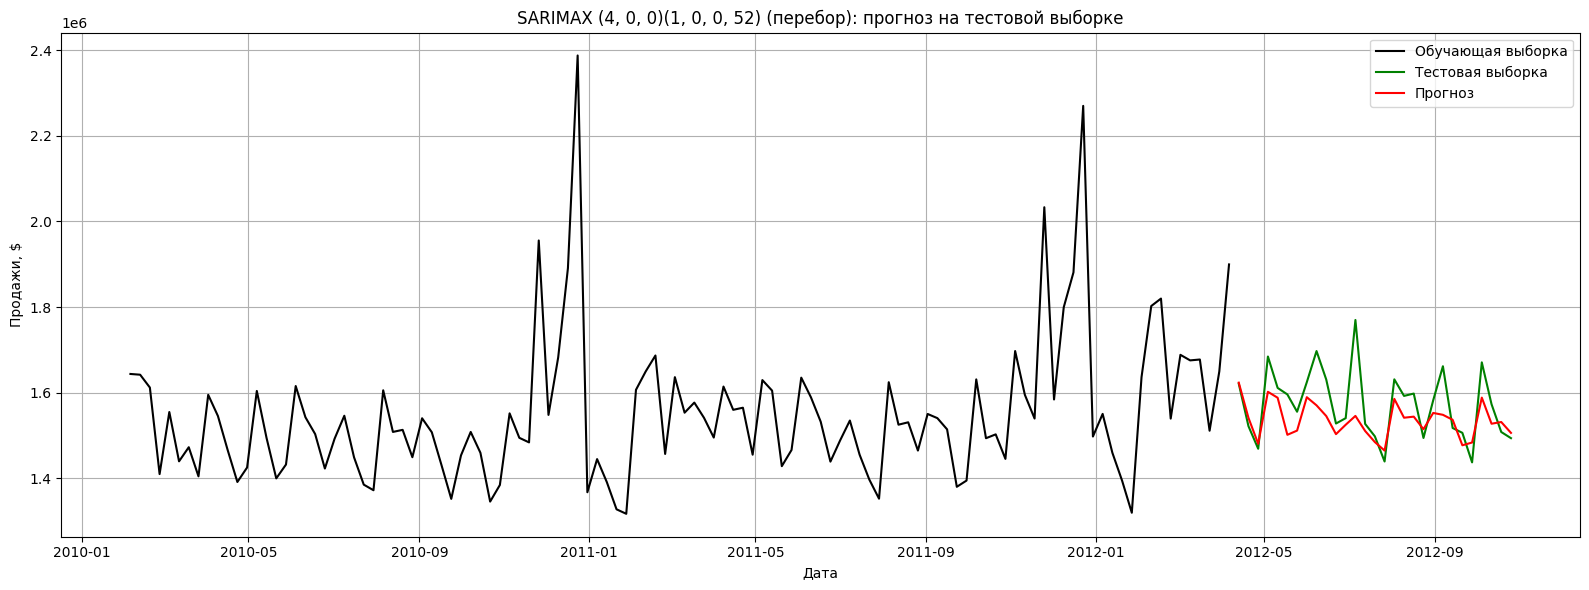

,model_name,params,R2,MAE
0,Baseline (среднее train),"const=1,551,089",-0.066782,67816.823376
1,ARIMA,"(4,0,0)",0.035195,64124.847068
2,SARIMAX,"(4,0,0)(0,0,1,52)",0.279819,51686.696482
3,auto_arima,"(4, 0, 2)(1, 0, 0, 52)",0.235638,52544.815109
4,SARIMAX by enumeration,"(4, 0, 0)(1, 0, 0, 52)",0.292471,48863.790127


In [ ]:
model_sarimax_en = SARIMAX(x_train.values,
                           order=best_params[:3],
                           seasonal_order=best_params[3:],
                           trend='c')   # константа, как при переборе
result = model_sarimax_en.fit(disp=False, maxiter=100)   # те же настройки, что в переборе

predictions = pd.Series(result.predict(start, end), index=x_test.index)
en_params = f'{best_params[:3]}{best_params[3:]}'
plot_prediction(x_train, x_test, predictions, f'SARIMAX {en_params} (перебор): прогноз на тестовой выборке')
model_char(x_test, predictions, 'SARIMAX by enumeration', en_params)

**Выводы по разделу:**

1. Лучшая модель по MAE — `SARIMAX(4,0,0)(1,0,0,52)` с константой: MAE = 48 864, R² = 0.292, что ≈28% лучше базового прогноза. Её несезонная часть `(4,0,0)` совпадает с выбранной по коррелограммам, отличается лишь сезонная: `P=1` вместо `Q=1`.

2. Модель из перебора подогнана под тестовую выборку (параметры выбраны по MAE на тесте), поэтому её результат оптимистичен. Разрыв между тремя лучшими моделями (48 864, 51 687 и 52 545) небольшой для 29 тестовых точек, поэтому уверенно ранжировать их нельзя.

3. Модели с сезонной компонентой `(P=1 или Q=1, m=52)` заметно превзошли `ARIMA(4,0,0)` без сезонности (MAE 64 125, всего ≈5% лучше базового прогноза).


## 10. Сравнение моделей

In [ ]:
df_model.sort_values(by='MAE', ascending=True, ignore_index=True)

,model_name,params,R2,MAE
0,SARIMAX by enumeration,"(4, 0, 0)(1, 0, 0, 52)",0.292471,48863.790127
1,SARIMAX,"(4,0,0)(0,0,1,52)",0.279819,51686.696482
2,auto_arima,"(4, 0, 2)(1, 0, 0, 52)",0.235638,52544.815109
3,ARIMA,"(4,0,0)",0.035195,64124.847068
4,Baseline (среднее train),"const=1,551,089",-0.066782,67816.823376


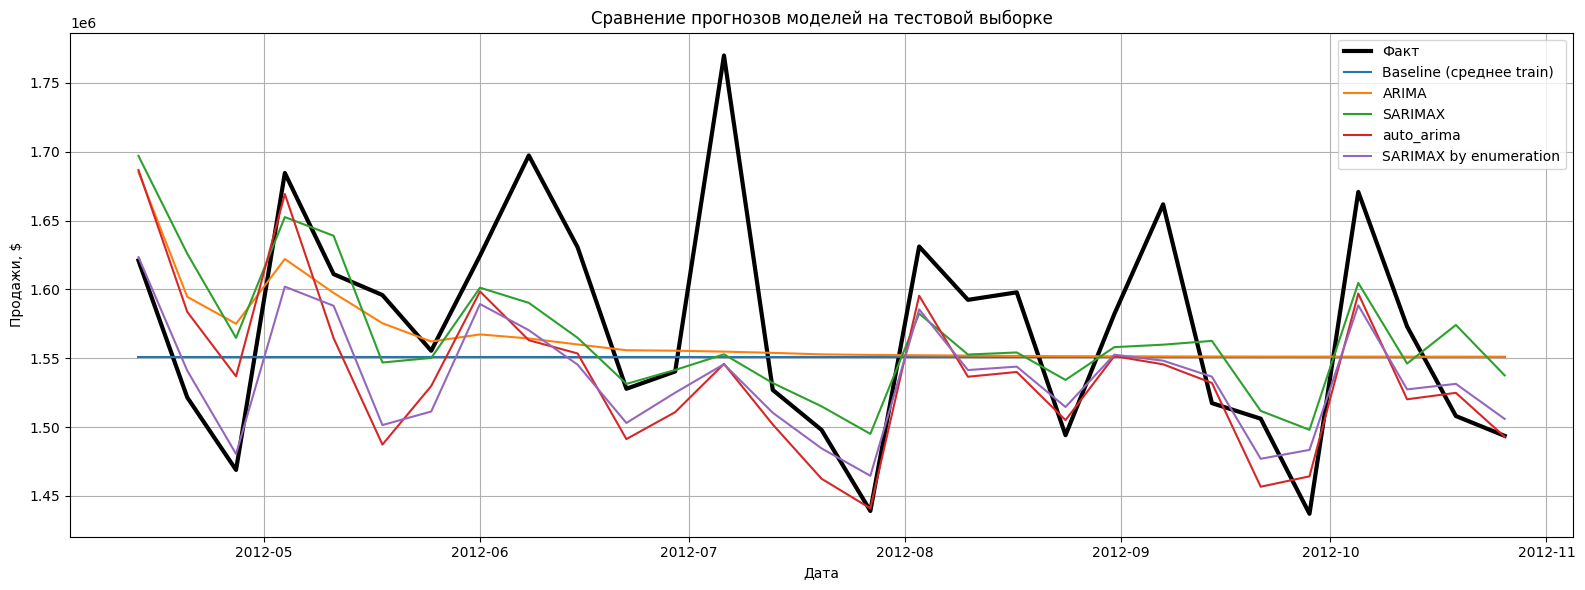

In [ ]:
# все прогнозы на одном графике (тестовый участок)
plt.figure(figsize=(16, 6))
plt.plot(x_test.index, x_test.values, color='black', linewidth=3, label='Факт')
for name, pred in predictions_all.items():
    plt.plot(x_test.index, pred, label=name)
plt.title('Сравнение прогнозов моделей на тестовой выборке')
plt.xlabel('Дата')
plt.ylabel('Продажи, $')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

In [ ]:
# автоматическая сводка по результатам
res = df_model.sort_values('MAE', ignore_index=True)
is_base = res['model_name'].str.startswith('Baseline')
base = res[is_base].iloc[0]
models = res[~is_base]
best, worst = models.iloc[0], models.iloc[-1]
print(f"Базовый прогноз (среднее по train): MAE = {base['MAE']:,.0f}, R2 = {base['R2']:.3f}, MAE = {base['MAE']/x_test.mean()*100:.1f}% от среднего на тесте")
print(f"Лучшая модель по MAE: {best['model_name']} {best['params']} -> MAE = {best['MAE']:,.0f}, R2 = {best['R2']:.3f}")
print(f"Худшая модель по MAE: {worst['model_name']} {worst['params']} -> MAE = {worst['MAE']:,.0f}, R2 = {worst['R2']:.3f}")
print()
print('Выигрыш MAE относительно базового прогноза:')
for _, r in models.iterrows():
    print(f"  {r['model_name']} {r['params']}: {(1 - r['MAE']/base['MAE'])*100:+.1f}%")
print(f"Среднее на тесте: {x_test.mean():,.0f}; std на тесте: {x_test.std():,.0f} ({x_test.std()/x_test.mean()*100:.1f}% от среднего)")


Базовый прогноз (среднее по train): MAE = 67,817, R2 = -0.067, MAE = 4.3% от среднего на тесте
Лучшая модель по MAE: SARIMAX by enumeration (4, 0, 0)(1, 0, 0, 52) -> MAE = 48,864, R2 = 0.292
Худшая модель по MAE: ARIMA (4,0,0) -> MAE = 64,125, R2 = 0.035

Выигрыш MAE относительно базового прогноза:
  SARIMAX by enumeration (4, 0, 0)(1, 0, 0, 52): +27.9%
  SARIMAX (4,0,0)(0,0,1,52): +23.8%
  auto_arima (4, 0, 2)(1, 0, 0, 52): +22.5%
  ARIMA (4,0,0): +5.4%
Среднее на тесте: 1,571,676; std на тесте: 81,075 (5.2% от среднего)


## 11. Выводы

В ходе работы были построены и протестированы модели ARIMA, SARIMAX (ручной подбор), auto_arima и SARIMAX с параметрами, подобранными перебором, а также базовый прогноз константой для недельных продаж магазина Walmart (2010–2012 гг.).

**Основные результаты:**

1. **Подготовка данных.** Ряд приведён к недельной частоте (`W-FRI`), проверен на пропуски и дубликаты (их нет). Тренда нет, есть годовая сезонность с пиками в конце ноября – декабре.

2. **Стационарность.** Тест Дики–Фуллера: p-value = 0.000014 < 0.05, ряд стационарен, `d = 0`.

3. **Коррелограммы.** ACF значим на лагах 1, 4 и 52 (отдельные всплески; лаги 2 и 3 незначимы; лаг 52 — годовая сезонность). PACF значим на лагах 1 и 4. Вручную выбрана модель `SARIMAX(4,0,0)(0,0,1,52)` с константой: `p=4` по максимальному значимому лагу PACF, `q=0` потому что всплески ACF на лагах 1 и 4 объясняются `AR(4)` и чёткого обрыва нет, `Q=1` по пику на лаге 52.

4. **Сравнение моделей** (по возрастанию MAE на тесте из 29 недель):

 - Все модели сравнивались на тестовой выборке из 29 недель. Лучший результат показала модель `SARIMAX(4,0,0)(1,0,0,52)`, подобранная перебором параметров: её MAE составило 48 864, что на 27.9% лучше базового прогноза (среднее по обучающей выборке, MAE = 67 817). R² этой модели равен 0.292.

 - На втором месте — модель `SARIMAX(4,0,0)(0,0,1,52)`, выбранная вручную по коррелограммам (с константой). Её MAE = 51 687 (выигрыш 23.8% относительно базового прогноза), R² = 0.280.

 - Третьей идёт модель `auto_arima (4,0,2)(1,0,0,52)` с MAE = 52 545 (выигрыш 22.5%) и R² = 0.236.

 - Модель `ARIMA(4,0,0)` без сезонной компоненты показала заметно худший результат: MAE = 64 125, R² = 0.035. Это подтверждает, что учёт годовой сезонности (период 52 недели) критически важен для данного ряда.

- Базовый прогноз (константа, равная среднему по train) дал MAE = 67 817 и R² = −0.067. Все построенные модели, кроме `ARIMA(4,0,0)`, обходят его с заметным отрывом.

5. **Лучшая модель — `SARIMAX(4,0,0)(1,0,0,52)` с константой** (найдена перебором с минимизацией MAE): `p=4, d=0, q=0` — несезонная часть, `P=1, D=0, Q=0, m=52` — сезонная. MAE = 48 864 (≈3,1% от среднего уровня продаж на тесте, 1 571 676 $), R² = 0.292.

6. **Пояснения.**
   - Процентная ошибка 3,1% сама по себе не показывает качество: базовый прогноз константой даёт 4,3%, потому что ряд в тесте колеблется лишь на ±5% вокруг среднего (std ≈ 81 тыс.). Реальный выигрыш лучшей модели — около 28% по MAE относительно базового прогноза.
   - R² = 0.292 означает, что модель объясняет около 29% дисперсии теста. Тестовый период (апрель–октябрь 2012) не содержит ноябрьско-декабрьских пиков, поэтому R² ограничен малой дисперсией теста и короткой выборкой (29 точек), а не «непредсказуемыми праздничными пиками».
   - `auto_arima` выбирает модель по AIC, а перебор — по MAE на тесте. Сезонная часть у них одинакова (`(1,0,0,52)`), отличается несезонная: у `auto_arima` добавлен `MA(2)`, но на тесте это не улучшило прогноз.
   - Несезонная часть лучшей модели `(4,0,0)` совпадает с выбранной по коррелограммам, то есть анализ ACF/PACF дал правильный ориентир для `p` и `q`. Ручная модель отличается от лучшей только сезонной компонентой (`Q=1` вместо `P=1`) и занимает второе место (MAE 51 687, R² 0.280). Разница между ними небольшая для 29 точек, поэтому делать вывод о преимуществе сезонной AR над сезонной MA осторожно.
   - Константа в `SARIMAX` существенна: без неё ручная модель давала отрицательный R² (−1.49), а с константой стала второй по качеству. `ARIMA` и `auto_arima` включают константу по умолчанию.
   - `ARIMA(4,0,0)` без сезонности лишь ≈5% лучше базового прогноза, то есть сезонная компонента с периодом 52 даёт основной выигрыш.

7. **Практические выводы:**
   - перебор по MAE на тесте даёт оптимистичную оценку (параметры подогнаны под тест), а разрыв между тремя лучшими моделями невелик; для честной оценки нужна отдельная валидационная выборка или скользящая кросс-валидация по времени;
   - на коротком ряду с периодом 52 (≈2,2 цикла на обучении) визуальный анализ ACF/PACF даёт хороший ориентир для несезонной части, а сезонную часть надёжнее проверять перебором;
   - для прогноза предпраздничных недель (ноябрь–декабрь) можно добавить экзогенные факторы (флаги праздников, промо) в SARIMAX; в данном тесте этих недель нет, поэтому проверить эффект на нём нельзя.

**Практическая значимость.** Модель `SARIMAX(4,0,0)(1,0,0,52)` с константой можно использовать для недельного прогноза продаж вне праздничного сезона: она примерно на 28% точнее прогноза средним уровнем. Для планирования ноябрьско-декабрьских пиков её нужно дополнять экзогенными факторами и проверять на данных, где эти пики есть.

